# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [1]:
# If on colab, uncomment the following lines

# ! wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', header=None).values
data = dataset[:, :-1].astype(int)
target = dataset[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    data, target, test_size=0.35, random_state=42, stratify=target
)
print(X_train.shape, X_test.shape)


(143, 19) (77, 19)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [3]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,169,50,49,-18,11,-6,48,-16,-3,6,30,-11,-18,10,40,20,-59,-9,31
1,167,-22,-7,-6,35,-5,12,-8,5,4,-20,-36,-16,16,5,-6,-68,21,-37
2,17,12,-5,-3,5,3,-22,18,-11,-5,-23,-3,6,16,19,-18,-19,8,-8
3,65,-26,26,9,-9,5,37,11,-12,11,-39,-9,7,11,8,-10,-5,-13,-23
4,82,-2,35,-1,-26,10,20,-2,23,17,39,-31,4,-11,-4,-18,-32,4,-8
5,163,21,-17,9,11,-1,-8,14,-42,2,-46,-18,9,17,-7,12,42,-22,-19
6,8,-37,-6,-12,34,8,-2,7,5,2,-89,9,23,-11,-3,-5,-50,-41,29
7,177,2,-20,0,37,-21,-6,-21,36,-3,8,-5,-27,-43,14,-9,-80,-35,-56
8,128,-21,-31,-2,17,-5,-8,-7,12,-8,37,-19,-55,35,7,5,-61,57,20
9,28,19,-2,-2,4,-8,-8,3,-2,-7,-16,-7,-13,12,18,-5,-30,-25,-10


Methods `describe` and `info` deliver some useful information.

In [4]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000,143.000000
mean,111.594406,-0.069930,-1.398601,-0.615385,4.972028,-0.251748,-0.608392,-0.853147,-2.727273,-0.930070,-14.307692,-2.867133,0.083916,1.216783,8.209790,-7.342657,-18.503497,-5.069930,-3.454545
std,64.002557,22.665557,22.178895,9.069313,23.298112,10.377025,22.231824,9.768416,18.848238,9.660177,40.650733,25.229158,22.181231,23.270346,21.746897,20.423373,48.790133,23.031409,23.567920
min,0.000000,-62.000000,-59.000000,-22.000000,-59.000000,-24.000000,-60.000000,-22.000000,-52.000000,-26.000000,-126.000000,-73.000000,-70.000000,-53.000000,-49.000000,-65.000000,-172.000000,-61.000000,-60.000000
25%,56.000000,-18.000000,-16.500000,-6.000000,-8.500000,-7.500000,-15.000000,-7.500000,-16.000000,-7.000000,-45.000000,-19.500000,-13.500000,-14.500000,-6.000000,-20.500000,-48.500000,-20.500000,-19.500000
50%,110.000000,2.000000,-2.000000,0.000000,5.000000,-1.000000,-1.000000,-1.000000,-2.000000,-1.000000,-15.000000,-5.000000,1.000000,2.000000,7.000000,-7.000000,-21.000000,-6.000000,-3.000000
75%,169.500000,14.500000,13.000000,5.000000,22.000000,6.500000,13.500000,5.500000,11.000000,5.500000,19.000000,16.000000,15.500000,17.000000,21.000000,7.000000,13.500000,10.500000,13.000000
max,219.000000,54.000000,65.000000,28.000000,59.000000,23.000000,50.000000,25.000000,48.000000,20.000000,83.000000,60.000000,51.000000,68.000000,61.000000,35.000000,88.000000,65.000000,57.000000


In [5]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       143 non-null    int64
 1   1       143 non-null    int64
 2   2       143 non-null    int64
 3   3       143 non-null    int64
 4   4       143 non-null    int64
 5   5       143 non-null    int64
 6   6       143 non-null    int64
 7   7       143 non-null    int64
 8   8       143 non-null    int64
 9   9       143 non-null    int64
 10  10      143 non-null    int64
 11  11      143 non-null    int64
 12  12      143 non-null    int64
 13  13      143 non-null    int64
 14  14      143 non-null    int64
 15  15      143 non-null    int64
 16  16      143 non-null    int64
 17  17      143 non-null    int64
 18  18      143 non-null    int64
dtypes: int64(19)
memory usage: 21.4 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

In [6]:
from sklearn.preprocessing import StandardScaler

# Первый столбец - номер строки, а не признак автомобиля
X_train = X_train[:, 1:]
X_test = X_test[:, 1:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Убрали первый столбец с номером объекта. Признаки имеют разный масштаб, поэтому использовали `StandardScaler`. Масштабирование обучаем только на train, затем применяем к test. Пропуски заполнять не нужно.


#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

Best params: {'C': 1}
Accuracy: 0.571
F1: 0.571


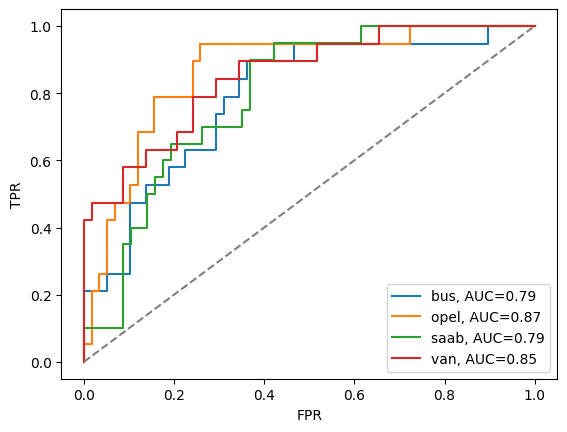

In [7]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize

def check_model(model, X, y):
    pred = model.predict(X)
    print('Accuracy:', round(accuracy_score(y, pred), 3))
    print('F1:', round(f1_score(y, pred, average='macro'), 3))

def plot_roc(model, X, y):
    probs = model.predict_proba(X)
    y_bin = label_binarize(y, classes=model.classes_)
    for i, name in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
        plt.plot(fpr, tpr, label=f'{name}, AUC={auc(fpr, tpr):.2f}')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel('FPR')
    plt.ylabel('TPR')
    plt.legend()
    plt.show()

lr_params = {'C': [0.1, 1, 10]}
lr = LogisticRegression(max_iter=1000, random_state=42)
lr_grid = GridSearchCV(lr, lr_params, cv=5, scoring='f1_macro')
lr_grid.fit(X_train_scaled, y_train)
lr_best = lr_grid.best_estimator_
print('Best params:', lr_grid.best_params_)
check_model(lr_best, X_test_scaled, y_test)
plot_roc(lr_best, X_test_scaled, y_test)


Параметр `C` подобрали с помощью кросс-валидации. По ROC-кривым можно сравнить классы: некоторые классы отделяются лучше других.


In [8]:
# You might use this command to install scikit-plot.
# Warning, if you a running locally, don't call pip from within jupyter, call it from terminal in the corresponding
# virtual environment instead

# ! pip install scikit-plot

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot.

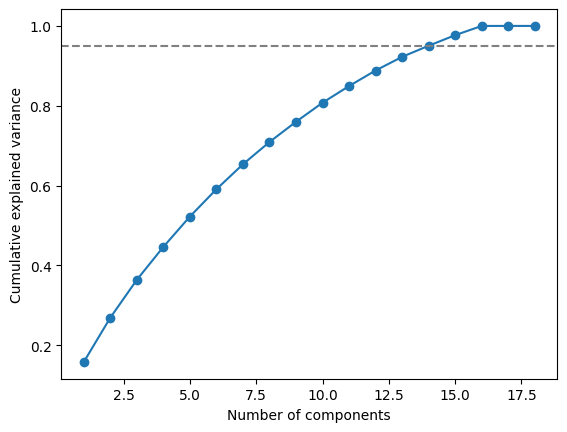

In [9]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(X_train_scaled)
var = pca_full.explained_variance_ratio_

plt.plot(range(1, len(var) + 1), np.cumsum(var), marker='o')
plt.axhline(0.95, linestyle='--', color='gray')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.show()


По графику видно, что первые несколько компонент объясняют основную часть дисперсии. Для дальнейшей работы возьмем компоненты, сохраняющие 95% дисперсии.


#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

In [10]:
pca = PCA(n_components=0.95)
pca.fit(X_train_scaled)
X_train_pca = pca.transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print('Components:', pca.n_components_)


Components: 14


Используем 95% дисперсии, чтобы уменьшить число признаков. Перед PCA нужна стандартизация, иначе признаки с большими значениями будут влиять сильнее остальных.


**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

Best params: {'C': 10}
Accuracy: 0.584
F1: 0.584


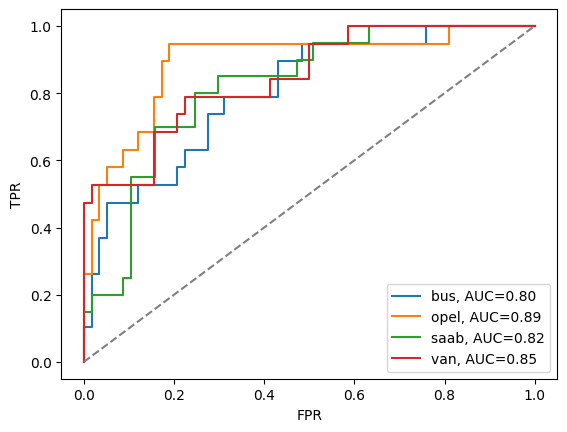

In [11]:
lr_pca_grid = GridSearchCV(lr, lr_params, cv=5, scoring='f1_macro')
lr_pca_grid.fit(X_train_pca, y_train)
lr_pca_best = lr_pca_grid.best_estimator_
print('Best params:', lr_pca_grid.best_params_)
check_model(lr_pca_best, X_test_pca, y_test)
plot_roc(lr_pca_best, X_test_pca, y_test)


После PCA качество может быть ниже: PCA сохраняет направления с большой дисперсией, но они не обязательно самые полезные для определения класса. Сравнение с обычной логистической регрессией видно по accuracy, F1 и ROC.


#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [12]:
from sklearn.tree import DecisionTreeClassifier

tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': [2, 4, 6, 8, 10, 12, 15]},
    cv=5, scoring='f1_macro'
)
tree_grid.fit(X_train_scaled, y_train)
tree_best = tree_grid.best_estimator_
print('Best depth:', tree_grid.best_params_['max_depth'])
check_model(tree_best, X_test_scaled, y_test)


Best depth: 6
Accuracy: 0.468
F1: 0.459


Глубину дерева выбрали по кросс-валидации. Слишком маленькая глубина может не учитывать важные зависимости, а большая - приводить к переобучению. Дереву масштабирование не обязательно.


#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble?

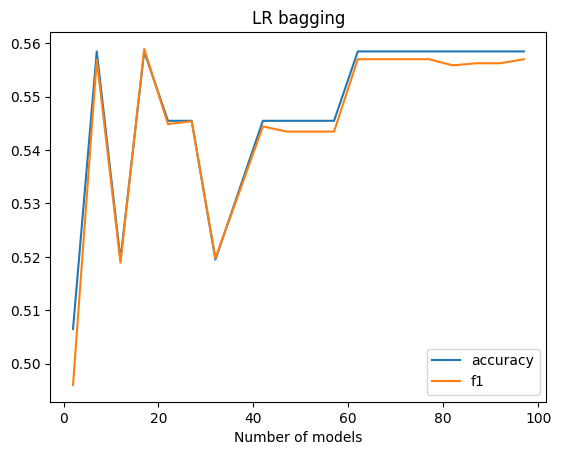

LR bagging best N: 17


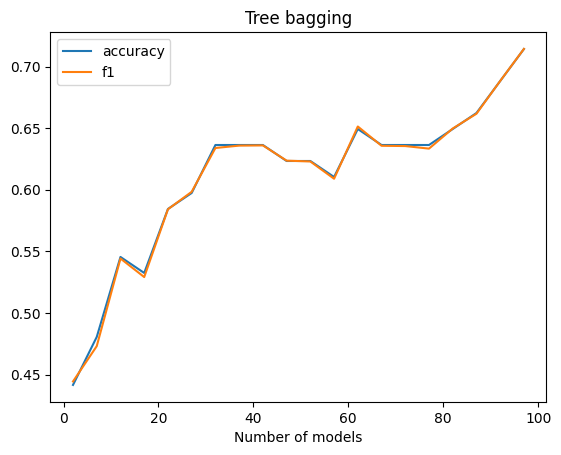

Tree bagging best N: 97


In [13]:
from sklearn.base import clone

sizes = list(range(2, 101, 5))
rng = np.random.RandomState(42)
boot = [rng.choice(len(X_train_scaled), len(X_train_scaled)) for _ in range(100)]

def bagging_scores(base_model):
    probabilities = []
    for idx in boot:
        model = clone(base_model).fit(X_train_scaled[idx], y_train[idx])
        probabilities.append(model.predict_proba(X_test_scaled))

    accuracy, f1 = [], []
    for n in sizes:
        pred = base_model.classes_[np.mean(probabilities[:n], axis=0).argmax(axis=1)]
        accuracy.append(accuracy_score(y_test, pred))
        f1.append(f1_score(y_test, pred, average='macro'))
    return accuracy, f1

lr_bag_acc, lr_bag_f1 = bagging_scores(lr_best)
tree_bag_acc, tree_bag_f1 = bagging_scores(tree_best)

for name, acc, f1 in [('LR bagging', lr_bag_acc, lr_bag_f1),
                      ('Tree bagging', tree_bag_acc, tree_bag_f1)]:
    plt.plot(sizes, acc, label='accuracy')
    plt.plot(sizes, f1, label='f1')
    plt.title(name)
    plt.xlabel('Number of models')
    plt.legend()
    plt.show()
    print(name, 'best N:', sizes[np.argmax(f1)])


Бэггинг для логистической регрессии обычно дает небольшой эффект: модели получаются похожими. Для деревьев усреднение полезнее, так как отдельные деревья нестабильны. По графикам можно выбрать число моделей, после которого качество почти не растет.

Глубина из задания 2.5 не обязательно лучшая для бэггинга. В ансамбле можно использовать более глубокие деревья, так как усреднение уменьшает переобучение.


#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

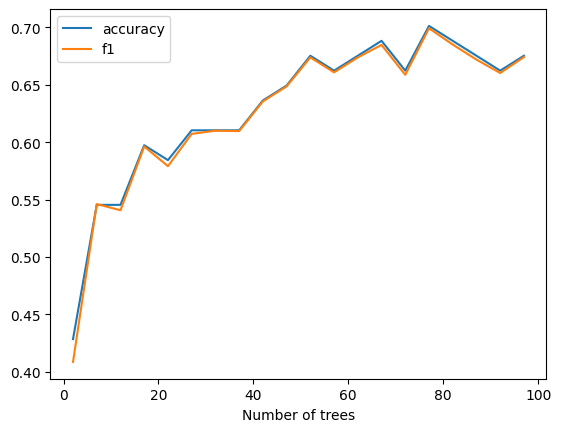

Best number of trees: 77


In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_acc, rf_f1 = [], []
for n in sizes:
    rf = RandomForestClassifier(n_estimators=n, random_state=42)
    rf.fit(X_train_scaled, y_train)
    pred = rf.predict(X_test_scaled)
    rf_acc.append(accuracy_score(y_test, pred))
    rf_f1.append(f1_score(y_test, pred, average='macro'))

plt.plot(sizes, rf_acc, label='accuracy')
plt.plot(sizes, rf_f1, label='f1')
plt.xlabel('Number of trees')
plt.legend()
plt.show()

best_n_trees = sizes[np.argmax(rf_f1)]
print('Best number of trees:', best_n_trees)


В случайном лесе качество сначала растет, затем обычно выходит на плато. Оптимальное число деревьев можно выбрать по графику. В отличие от обычного бэггинга деревья в лесу используют случайные наборы признаков, поэтому они менее похожи друг на друга.


#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it?

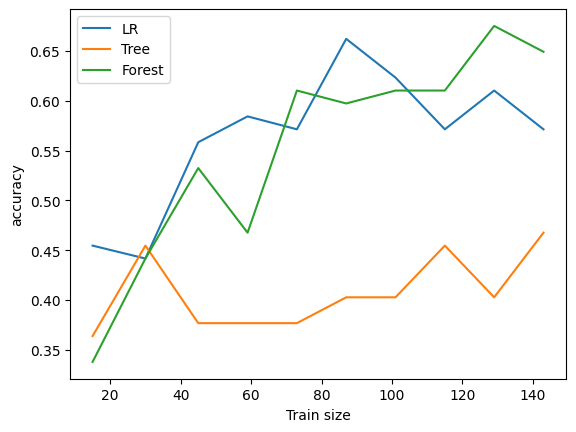

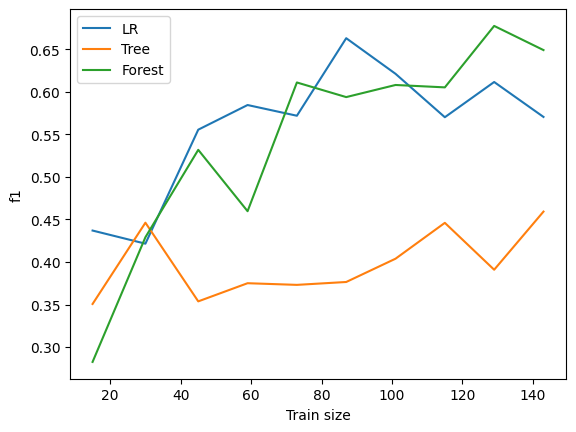

In [15]:
models = {
    'LR': lr_best,
    'Tree': tree_best,
    'Forest': RandomForestClassifier(n_estimators=best_n_trees, random_state=42)
}
idx = np.random.RandomState(42).permutation(len(X_train_scaled))
parts = np.array_split(idx, 10)
train_sizes = []
scores = {name: {'accuracy': [], 'f1': []} for name in models}

for k in range(1, 11):
    ids = np.concatenate(parts[:k])
    train_sizes.append(len(ids))
    for name, model in models.items():
        m = clone(model).fit(X_train_scaled[ids], y_train[ids])
        pred = m.predict(X_test_scaled)
        scores[name]['accuracy'].append(accuracy_score(y_test, pred))
        scores[name]['f1'].append(f1_score(y_test, pred, average='macro'))

for metric in ['accuracy', 'f1']:
    for name in models:
        plt.plot(train_sizes, scores[name][metric], label=name)
    plt.xlabel('Train size')
    plt.ylabel(metric)
    plt.legend()
    plt.show()


По learning curve видно, как меняется качество при увеличении train. В начале дополнительная выборка обычно помогает, позже рост замедляется. Также можно сравнить, какая из трех моделей лучше работает на маленькой выборке.


#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

In [16]:
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y_tr = encoder.fit_transform(y_train)
y_te = encoder.transform(y_test)
dtrain = xgb.DMatrix(X_train_scaled, label=y_tr)
dtest = xgb.DMatrix(X_test_scaled, label=y_te)

params = {
    'objective': 'multi:softprob',
    'num_class': len(encoder.classes_),
    'eval_metric': 'mlogloss',
    'max_depth': 3,
    'eta': 0.1,
    'seed': 42
}
cv_result = xgb.cv(params, dtrain, num_boost_round=200,
                   nfold=3, stratified=True, early_stopping_rounds=15, seed=42)
best_rounds = len(cv_result)
print('Best number of trees:', best_rounds)

booster = xgb.train(params, dtrain, num_boost_round=best_rounds)
pred = encoder.inverse_transform(booster.predict(dtest).argmax(axis=1))
print('Accuracy:', round(accuracy_score(y_test, pred), 3))
print('F1:', round(f1_score(y_test, pred, average='macro'), 3))


Best number of trees: 26
Accuracy: 0.597
F1: 0.597


Использовали XGBoost без sklearn API. Число деревьев выбрали по кросс-валидации с ранней остановкой: если ошибка на валидации перестает уменьшаться, добавлять деревья дальше нет смысла.
